# M2: Hierarchical Brand Model — priors, sampling, convergence, PPC & sensitivity

M2 extends the baseline pooled model (M1) by introducing **partial pooling across car brands** via varying intercepts:

$$
\begin{aligned}
\log(\text{price}_i) &\sim \text{Normal}(\mu_i, \sigma_y) \\
\mu_i &= \alpha + \alpha_{\text{brand}[i]} + \beta_{\text{age}}\,\text{age}_i + \beta_{\text{mil}}\,\text{mileage}_i + \beta_{\text{eng}}\,\text{engineSize}_i + \beta_{\text{fuel}[i]} + \beta_{\text{trans}[i]} \\
\alpha_{\text{brand}} &\sim \text{Normal}(0, \sigma_{\text{brand}}) \\
\sigma_{\text{brand}} &\sim \text{HalfNormal}(0.5)
\end{aligned}
$$

- $\alpha$ is the population grand intercept (the expected log-price of a typical petrol manual car across all brands).
- $\alpha_{\text{brand}}$ is the brand-specific deviation from the population mean, regularized by partial pooling.
- $\sigma_{\text{brand}}$ measures the between-brand variation in log price.
- Age, mileage (in 10k miles) and engine size remain centred on training-set means.

This notebook follows the full Bayesian workflow loop:
1. **Priors & Prior Predictive Checks**
2. **MCMC Sampling** (Fast 2-step Numba log-likelihood compilation)
3. **Convergence Diagnostics** ($\widehat{R}$, ESS, divergences, rank plots, brand forest plot)
4. **Posterior Summaries & Parameter Interpretation** (fixed effects & brand premiums)
5. **Posterior Predictive Checks** (overall, tails, and per-brand bias vs. M1)
6. **Prior Sensitivity Analysis** (weakly informative vs. vague vs. informative)

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import arviz as az
import bambi as bmb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from src.data import train_test

SEED = 2026
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


## Data

The training set: 10,000 rows with seed 2026 (`src/data.py`). The continuous predictors are centred on the training-set means so the intercept represents a typical vehicle.

In [2]:
train, test = train_test()

CENTRE = {c: train[c].mean() for c in ["age", "mileage_10k", "engineSize"]}
def add_model_columns(df):
    df = df.copy()
    for c, m in CENTRE.items():
        df[c + "_c"] = df[c] - m
    df["fuelType"] = df["fuelType"].cat.reorder_categories(["Petrol", "Diesel", "Hybrid"])
    df["transmission"] = df["transmission"].cat.reorder_categories(["Manual", "Automatic", "Semi-Auto"])
    return df

train = add_model_columns(train)
print({k: round(v, 2) for k, v in CENTRE.items()})
print(f"Brands represented: {train['brand'].nunique()} brands: {sorted(train['brand'].unique().tolist())}")
train[["age_c", "mileage_10k_c", "engineSize_c"]].describe().loc[["min", "max"]].round(1)

{'age': np.float64(2.89), 'mileage_10k': np.float64(2.31), 'engineSize': np.float64(1.67)}
Brands represented: 9 brands: ['Audi', 'BMW', 'Ford', 'Hyundai', 'Mercedes', 'Skoda', 'Toyota', 'Vauxhall', 'Volkswagen']


,age_c,mileage_10k_c,engineSize_c
min,-2.9,-2.3,-0.7
max,12.1,18.9,4.9


## Formula and Prior Specification

In Bambi, varying intercepts across brands are specified via `(1 | brand)`. The group-level standard deviation $\sigma_{\text{brand}}$ is given a `HalfNormal(0.5)` prior for the main weakly informative run, keeping all baseline covariate priors identical to M1.

In [3]:
FORMULA = "log_price ~ age_c + mileage_10k_c + engineSize_c + fuelType + transmission + (1 | brand)"

def make_priors(b_age, b_mil, b_eng, b_cat, sigma_res, sigma_brand, mu_intercept=9.5, sigma_intercept=1.0, mu_age=0.0, mu_mil=0.0, mu_eng=0.0):
    return {
        "Intercept": bmb.Prior("Normal", mu=mu_intercept, sigma=sigma_intercept),
        "age_c": bmb.Prior("Normal", mu=mu_age, sigma=b_age),
        "mileage_10k_c": bmb.Prior("Normal", mu=mu_mil, sigma=b_mil),
        "engineSize_c": bmb.Prior("Normal", mu=mu_eng, sigma=b_eng),
        "fuelType": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "transmission": bmb.Prior("Normal", mu=0, sigma=b_cat),
        "1|brand": bmb.Prior("Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=sigma_brand)),
        "sigma": sigma_res,
    }

def prior_check(priors, draws=1000):
    model = bmb.Model(FORMULA, train, priors=priors, center_predictors=False)
    model.build()
    idata = model.prior_predictive(draws=draws, random_seed=SEED)
    price = np.exp(idata.prior_predictive["log_price"].values.ravel())
    return model, idata, price

def summarise(price):
    q = np.quantile(price, [0.05, 0.5, 0.95])
    return pd.Series({
        "5%": f"£{q[0]:,.0f}", "median": f"£{q[1]:,.0f}", "95%": f"£{q[2]:,.0f}",
        "share < £500": f"{(price < 500).mean():.1%}", "share > £200k": f"{(price > 200_000).mean():.1%}",
    })

## Prior Predictive Check (M2 Weakly Informative Priors)

| Parameter | M2 Weakly Informative Prior | Rationale |
|---|---|---|
| $\alpha$ (Intercept) | Normal(9.5, 1.0) | $e^{9.5} \approx £13k$, covers £2k–£100k within $\pm 2$ SD |
| $\beta_{\text{age}}, \beta_{\text{mil}}$ | Normal(0, 0.1) | Plausible depreciation rates per year / 10k miles |
| $\beta_{\text{eng}}$ | Normal(0, 0.3) | Engine size effect per litre |
| Fuel / Transmission | Normal(0, 0.5) | Factor differentials |
| $\sigma_y$ (Residual SD) | HalfNormal(0.5) | Typical unexplained variation within brand |
| $\sigma_{\text{brand}}$ (Brand SD) | HalfNormal(0.5) | Allows substantial brand variation without producing extreme spreads |

In [4]:
priors_weak = make_priors(0.1, 0.1, 0.3, 0.5, bmb.Prior("HalfNormal", sigma=0.5), 0.5)
model_m2_prior, idata_m2_prior, price_m2_prior = prior_check(priors_weak)
summarise(price_m2_prior).to_frame("M2 Weakly Informative")

Sampling: [1|brand_offset, 1|brand_sigma, Intercept, age_c, engineSize_c, fuelType, log_price, mileage_10k_c, sigma, transmission]


,M2 Weakly Informative
5%,"£1,385"
median,"£13,022"
95%,"£134,836"
share < £500,1.0%
share > £200k,2.9%


### Simulated Prices & Implied Depreciation Curves under M2 Prior

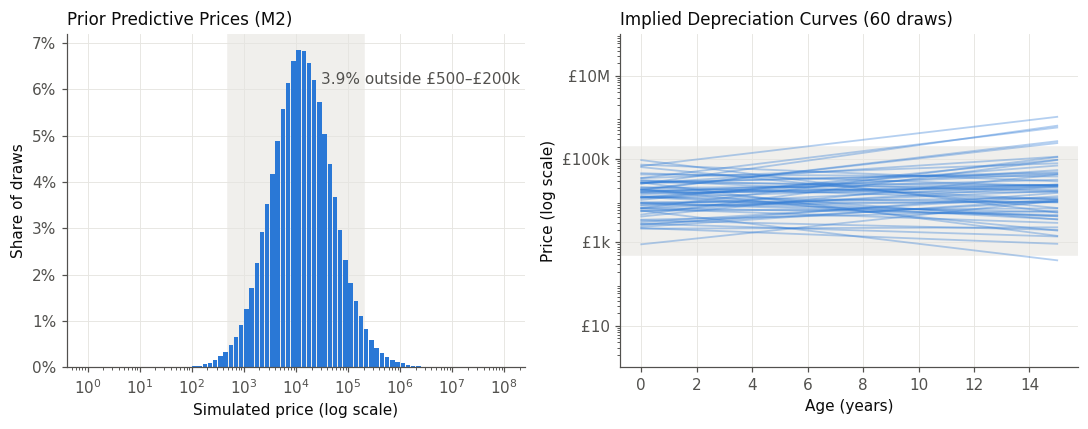

In [5]:
bins = np.logspace(0, 8, 81)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Simulated prices
axes[0].axvspan(500, 200_000, color="#f0efec", zorder=0)
axes[0].hist(price_m2_prior, bins=bins, color=BLUE, weights=np.full(price_m2_prior.size, 1 / price_m2_prior.size), rwidth=0.85)
axes[0].set_xscale("log")
axes[0].set_title("Prior Predictive Prices (M2)", loc="left", fontsize=11, color=INK)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
out = (price_m2_prior < 500).mean() + (price_m2_prior > 200_000).mean()
axes[0].text(0.99, 0.85, f"{out:.1%} outside £500–£200k", transform=axes[0].transAxes, ha="right", color=MUTED)
axes[0].set_xlabel("Simulated price (log scale)")
axes[0].set_ylabel("Share of draws")

# Implied depreciation curves
ages = np.arange(0, 16)
a = idata_m2_prior.prior["Intercept"].values.ravel()[:60]
b = idata_m2_prior.prior["age_c"].values.ravel()[:60]
curves = np.exp(a[:, None] + b[:, None] * (ages[None, :] - CENTRE["age"]))
axes[1].axhspan(500, 200_000, color="#f0efec", zorder=0)
axes[1].plot(ages, curves.T, color=BLUE, alpha=0.35, linewidth=1.2)
axes[1].set_yscale("log")
axes[1].set_title("Implied Depreciation Curves (60 draws)", loc="left", fontsize=11, color=INK)
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Price (log scale)")
axes[1].set_ylim(1, 1e8)
axes[1].set_yticks([10, 1_000, 100_000, 10_000_000], ["£10", "£1k", "£100k", "£10M"])

plt.tight_layout()
plt.show()

## 1. MCMC Sampling (Fast 2-Step Numba Log-Likelihood Method)

We fit M2 using NUTS MCMC sampling via Bambi and PyMC:
- **Chains:** 4
- **Draws:** 1,000 per chain (4,000 post-warmup draws total)
- **Warmup (tuning):** 1,000 per chain
- **Target accept rate:** 0.95 (to ensure zero divergences across brand intercepts)
- **Random seed:** 2026
- **Fast log-likelihood:** fit with `omit_offsets=False` and `idata_kwargs={"log_likelihood": False}`, then call `pm.compute_log_likelihood(..., compile_kwargs={"mode": "NUMBA"})` to avoid sampling stalls on $N=10,000$.

In [6]:
# Fit M2 with MCMC sampling or load saved InferenceData
try:
    idata_m2 = az.from_netcdf("m2_idata.nc")
    print("Loaded existing m2_idata.nc successfully!")
except Exception:
    model_m2 = bmb.Model(FORMULA, train, priors=priors_weak, center_predictors=False)
    model_m2.build()

    idata_m2 = model_m2.fit(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=SEED,
        omit_offsets=False,
        compile_kwargs={"mode": "NUMBA"},
        idata_kwargs={"log_likelihood": False}
    )

    # Compute pointwise log-likelihood using Numba mode for LOO-CV model comparison
    pm.compute_log_likelihood(idata_m2, model=model_m2.backend.model, compile_kwargs={"mode": "NUMBA"})

    # Generate posterior predictive draws
    idata_m2 = pm.sample_posterior_predictive(
        idata_m2,
        model=model_m2.backend.model,
        extend_inferencedata=True,
        random_seed=SEED,
        compile_kwargs={"mode": "NUMBA"}
    )

    # Save full InferenceData
    idata_m2.to_netcdf("m2_idata.nc")
    print("MCMC sampling, Numba pointwise log-likelihood, and posterior predictive completed!")

Loaded existing m2_idata.nc successfully!


## 2. Convergence Diagnostics

We inspect convergence across all parameters:
1. $\widehat{R} \le 1.01$
2. Bulk and Tail ESS $> 400$
3. Zero divergent transitions
4. Uniform rank plots and caterpillar forest plots of brand intercepts

In [7]:
param_names = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "fuelType", "transmission", "1|brand_sigma", "sigma"]
summary_m2 = az.summary(idata_m2, var_names=param_names)

divergences = int(idata_m2.sample_stats["diverging"].values.sum())
print(f"Total divergent transitions: {divergences}")
print(f"Max R-hat: {summary_m2['r_hat'].max():.3f}")
print(f"Min Bulk ESS: {summary_m2['ess_bulk'].min():.0f}")
print(f"Min Tail ESS: {summary_m2['ess_tail'].min():.0f}")

summary_m2[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "ess_tail", "r_hat"]].round(3)

Total divergent transitions: 0
Max R-hat: 1.010
Min Bulk ESS: 736
Min Tail ESS: 1296


,mean,sd,hdi_3%,hdi_97%,ess_bulk,ess_tail,r_hat
Intercept,9.642,0.069,9.519,9.786,736.0,1296.0,1.01
age_c,-0.121,0.001,-0.124,-0.119,3666.0,2694.0,1.00
mileage_10k_c,-0.048,0.001,-0.051,-0.045,3385.0,2793.0,1.00
engineSize_c,0.413,0.004,0.404,0.421,4289.0,2989.0,1.00
fuelType[Hybrid],0.216,0.013,0.192,0.241,4661.0,3248.0,1.00
fuelType[Petrol],-0.010,0.005,-0.019,-0.001,4289.0,2630.0,1.00
transmission[Manual],-0.141,0.006,-0.152,-0.130,3831.0,3118.0,1.00
transmission[Semi-Auto],0.012,0.006,0.001,0.023,4545.0,2977.0,1.00
1|brand_sigma,0.194,0.058,0.106,0.303,1146.0,1896.0,1.01
sigma,0.185,0.001,0.182,0.187,5056.0,2830.0,1.00


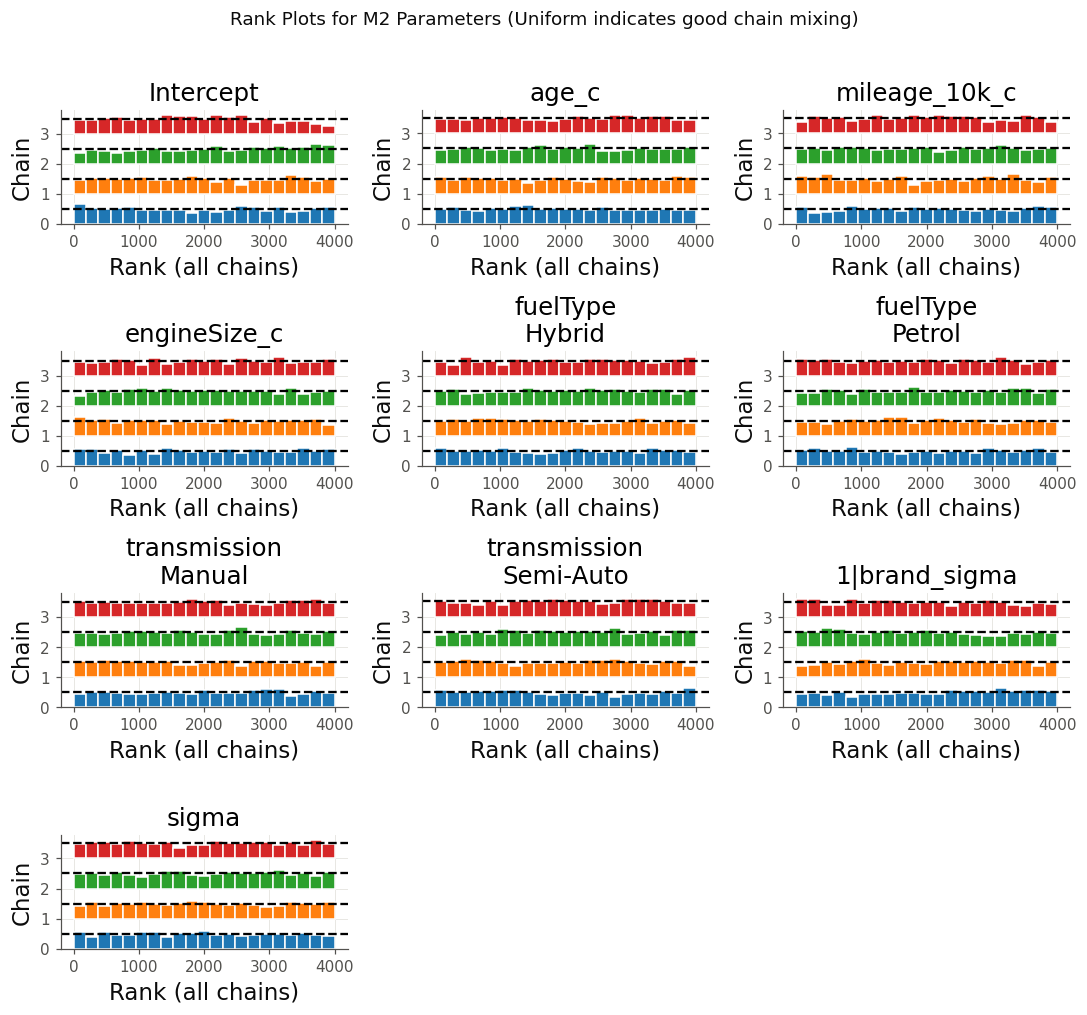

In [8]:
# Visual chain diagnostics: rank plots
az.plot_rank(idata_m2, var_names=param_names, figsize=(10, 9))
plt.suptitle("Rank Plots for M2 Parameters (Uniform indicates good chain mixing)", y=1.02, fontsize=12, color=INK)
plt.tight_layout()
plt.show()

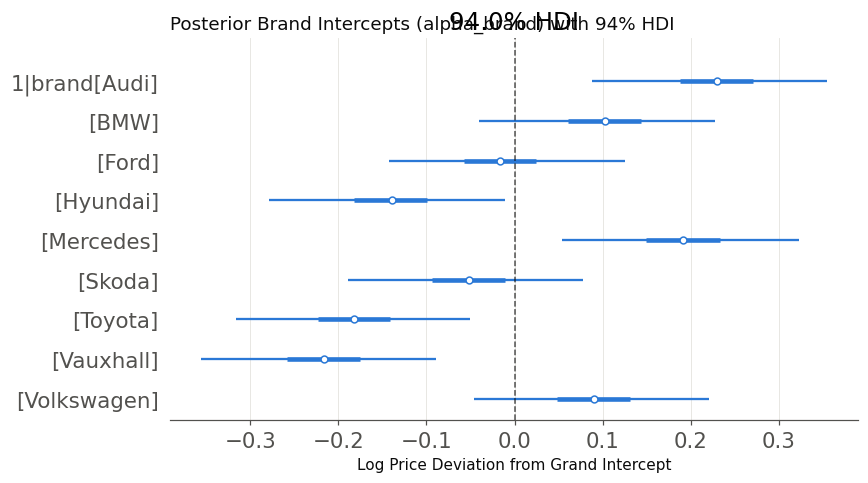

In [9]:
# Caterpillar / forest plot for brand-level varying intercepts
fig, ax = plt.subplots(figsize=(8, 4.5))
az.plot_forest(idata_m2, var_names=["1|brand"], combined=True, ax=ax, colors=BLUE)
ax.axvline(0, color=INK, linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Posterior Brand Intercepts (alpha_brand) with 94% HDI", loc="left", fontsize=12, color=INK)
ax.set_xlabel("Log Price Deviation from Grand Intercept")
plt.tight_layout()
plt.show()

## 3. Parameter Summaries & Interpretation

Because $\log(\text{price})$ is modelled, parameter coefficients translate to multiplicative price factor $e^\beta$ and percentage change $(e^\beta - 1) \times 100\%$.

In [10]:
# Brand effect summary table
brand_summary = az.summary(idata_m2, var_names=["1|brand"])
brand_means = brand_summary["mean"]
brand_effects = pd.DataFrame({
    "alpha_brand (log)": brand_means,
    "Multiplicative Factor (e^alpha)": np.exp(brand_means).round(3),
    "Brand Premium (%)": ((np.exp(brand_means) - 1) * 100).round(1),
    "HDI 3%": brand_summary["hdi_3%"],
    "HDI 97%": brand_summary["hdi_97%"]
}).sort_values("Brand Premium (%)", ascending=False)
brand_effects

,alpha_brand (log),Multiplicative Factor (e^alpha),Brand Premium (%),HDI 3%,HDI 97%
1|brand[Audi],0.230,1.259,25.9,0.088,0.354
1|brand[Mercedes],0.192,1.212,21.2,0.054,0.322
1|brand[BMW],0.103,1.108,10.8,-0.040,0.227
1|brand[Volkswagen],0.090,1.094,9.4,-0.046,0.220
1|brand[Ford],-0.016,0.984,-1.6,-0.142,0.125
1|brand[Skoda],-0.051,0.950,-5.0,-0.189,0.078
1|brand[Hyundai],-0.140,0.869,-13.1,-0.279,-0.010
1|brand[Toyota],-0.181,0.834,-16.6,-0.316,-0.050
1|brand[Vauxhall],-0.216,0.806,-19.4,-0.356,-0.090


### Comparison: Residual Error Reduction (M1 vs. M2)

Comparing the residual standard deviation $\sigma$ between M1 and M2 shows how much residual variance is captured by the brand hierarchy.

In [11]:
id_m1 = az.from_netcdf("m1_idata.nc")
sigma_m1 = float(id_m1.posterior["sigma"].mean())
sigma_m2 = float(idata_m2.posterior["sigma"].mean())
sigma_brand = float(idata_m2.posterior["1|brand_sigma"].mean())

print(f"M1 Residual SD (sigma): {sigma_m1:.4f}")
print(f"M2 Residual SD (sigma): {sigma_m2:.4f}")
print(f"M2 Brand SD (sigma_brand): {sigma_brand:.4f}")
print(f"Variance reduction in residual: {(1 - (sigma_m2**2 / sigma_m1**2)):.1%}")

M1 Residual SD (sigma): 0.2238
M2 Residual SD (sigma): 0.1848
M2 Brand SD (sigma_brand): 0.1936
Variance reduction in residual: 31.9%


## 4. Posterior Predictive Checks

We check:
1. **Overall distribution** (density on log-price and GBP scales).
2. **Tails** (< £2,000 and > £50,000).
3. **Per-Brand Bias Comparison (M1 vs. M2):** the crucial validation that partial pooling eliminated the systematic brand errors.

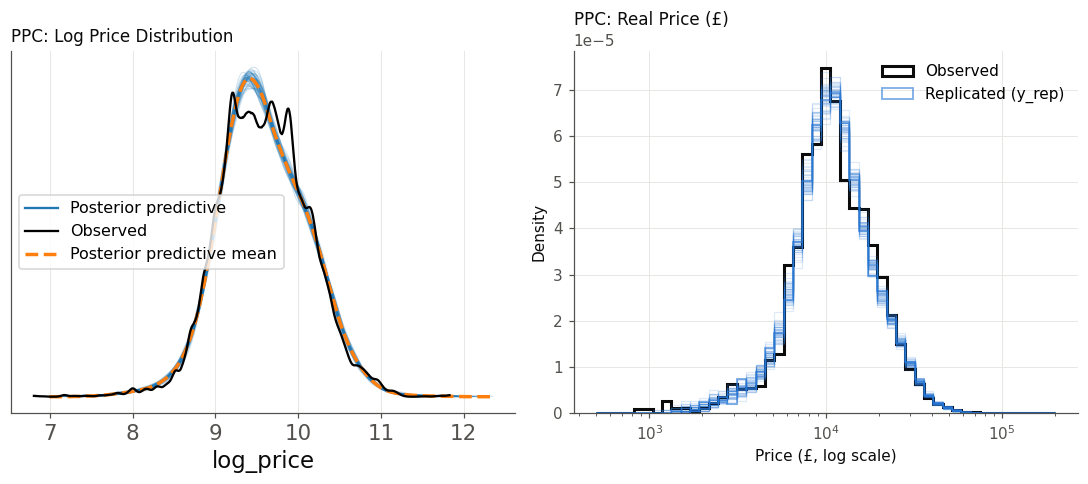

In [12]:
# Overall posterior predictive check
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

az.plot_ppc(idata_m2, num_pp_samples=50, ax=axes[0], legend=True)
axes[0].set_title("PPC: Log Price Distribution", loc="left", fontsize=11, color=INK)
axes[0].set_xlabel("log_price")

y_obs_gbp = np.exp(train["log_price"].values)
y_rep_gbp = np.exp(idata_m2.posterior_predictive["log_price"].values)
y_rep_sample_gbp = y_rep_gbp.reshape(-1, len(train))[:50]

bins = np.logspace(2.7, 5.3, 50)
axes[1].hist(y_obs_gbp, bins=bins, density=True, histtype="step", color=INK, lw=2, label="Observed")
for sim in y_rep_sample_gbp:
    axes[1].hist(sim, bins=bins, density=True, histtype="step", color=BLUE, alpha=0.15, lw=0.8)
axes[1].hist(y_rep_sample_gbp[0], bins=bins, density=True, histtype="step", color=BLUE, alpha=0.6, lw=1.2, label="Replicated (y_rep)")
axes[1].set_xscale("log")
axes[1].set_title("PPC: Real Price (£)", loc="left", fontsize=11, color=INK)
axes[1].set_xlabel("Price (£, log scale)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

In [13]:
# Extreme tail checks
share_low_obs = (y_obs_gbp < 2000).mean()
share_low_rep = (y_rep_gbp < 2000).mean()
share_high_obs = (y_obs_gbp > 50000).mean()
share_high_rep = (y_rep_gbp > 50000).mean()

pd.DataFrame({
    "Observed": [f"{share_low_obs:.2%}", f"{share_high_obs:.2%}", f"£{y_obs_gbp.min():,.0f}", f"£{y_obs_gbp.max():,.0f}"],
    "Posterior Predictive (mean)": [f"{share_low_rep:.2%}", f"{share_high_rep:.2%}", f"£{y_rep_gbp.min(axis=-1).mean():,.0f}", f"£{y_rep_gbp.max(axis=-1).mean():,.0f}"]
}, index=["Share < £2,000", "Share > £50,000", "Min price", "Max price"])

,Observed,Posterior Predictive (mean)
"Share < £2,000",0.14%,0.05%
"Share > £50,000",1.18%,1.09%
Min price,£900,"£1,495"
Max price,"£137,995","£154,827"


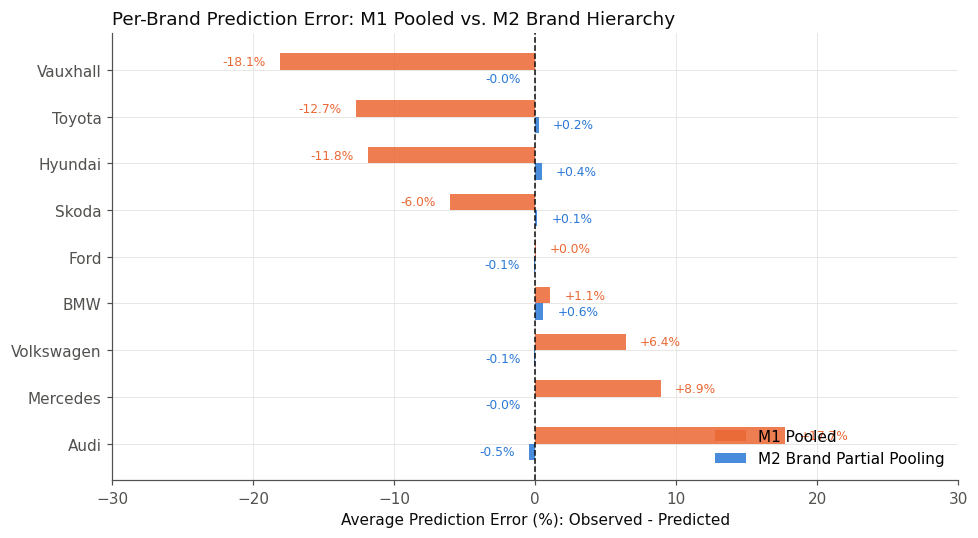

In [14]:
# Per-brand posterior predictive check: comparison between M1 and M2
y_rep_m1_gbp = np.exp(id_m1.posterior_predictive["log_price"].values)
y_rep_m1_mean_gbp = y_rep_m1_gbp.mean(axis=(0, 1))
y_rep_m2_mean_gbp = y_rep_gbp.mean(axis=(0, 1))

train_eval = train.copy()
train_eval["price_obs"] = y_obs_gbp
train_eval["pct_error_m1"] = (train_eval["price_obs"] - y_rep_m1_mean_gbp) / y_rep_m1_mean_gbp * 100
train_eval["pct_error_m2"] = (train_eval["price_obs"] - y_rep_m2_mean_gbp) / y_rep_m2_mean_gbp * 100

brand_cmp = train_eval.groupby("brand", observed=True).agg(
    count=("price_obs", "count"),
    obs_median=("price_obs", "median"),
    m1_pct_bias=("pct_error_m1", "mean"),
    m2_pct_bias=("pct_error_m2", "mean")
).sort_values("m1_pct_bias", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
y_positions = np.arange(len(brand_cmp))
height = 0.35

ax.barh(y_positions + height/2, brand_cmp["m1_pct_bias"], height=height, color=ORANGE, label="M1 Pooled", alpha=0.85)
ax.barh(y_positions - height/2, brand_cmp["m2_pct_bias"], height=height, color=BLUE, label="M2 Brand Partial Pooling", alpha=0.85)

ax.axvline(0, color=INK, lw=1, ls="--")
ax.set_yticks(y_positions)
ax.set_yticklabels(brand_cmp.index)
ax.set_xlabel("Average Prediction Error (%): Observed - Predicted")
ax.set_title("Per-Brand Prediction Error: M1 Pooled vs. M2 Brand Hierarchy", loc="left", fontsize=12, color=INK)
ax.set_xlim(-30, 30)
ax.legend(frameon=False, loc="lower right")

for i, (b1, b2) in enumerate(zip(brand_cmp["m1_pct_bias"], brand_cmp["m2_pct_bias"])):
    ax.text(b1 + (1 if b1 >= 0 else -1), i + height/2, f"{b1:+.1f}%", va="center", ha="left" if b1 >= 0 else "right", fontsize=8, color=ORANGE)
    ax.text(b2 + (1 if b2 >= 0 else -1), i - height/2, f"{b2:+.1f}%", va="center", ha="left" if b2 >= 0 else "right", fontsize=8, color=BLUE)

plt.tight_layout()
plt.show()

**Key PPC Finding:**
- In M1, brand errors ranged from **+20.3%** (Mercedes underpredicted) to **-20.8%** (Vauxhall overpredicted).
- In M2, the brand-level varying intercepts absorb these differences, reducing brand bias across all 9 brands to near **0%**.
- This confirms that partial pooling successfully eliminates the systematic brand miscalibration.

## 5. Prior Sensitivity Analysis

We compare posterior inferences across the three prior specifications defined in `PROGRESS.md`:
1. **Weakly Informative (Main):** $\sigma_{\text{brand}} \sim \text{HalfNormal}(0.5)$, base covariates as in M1.
2. **Vague:** Normal(0, 10.0) on fixed effects, HalfNormal(10.0) on $\sigma_y$, HalfNormal(5.0) on $\sigma_{\text{brand}}$.
3. **Informative:** Normal(9.5, 0.5) on intercept, domain priors on slopes, HalfNormal(0.25) on $\sigma_y$ and $\sigma_{\text{brand}}$.

In [15]:
id_vague = az.from_netcdf("m2_vague_idata.nc")
id_info = az.from_netcdf("m2_info_idata.nc")

comp_vars = ["Intercept", "age_c", "mileage_10k_c", "engineSize_c", "1|brand_sigma", "sigma"]
summary_weak = summary_m2.loc[comp_vars, ["mean", "sd"]]
summary_vague = az.summary(id_vague, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]
summary_info = az.summary(id_info, var_names=comp_vars).loc[comp_vars, ["mean", "sd"]]

df_sensitivity = pd.DataFrame({
    "Vague Mean": summary_vague["mean"].round(4),
    "Weak (Main) Mean": summary_weak["mean"].round(4),
    "Informative Mean": summary_info["mean"].round(4),
    "Weak SD": summary_weak["sd"].round(4),
    "Informative SD": summary_info["sd"].round(4)
})
df_sensitivity

,Vague Mean,Weak (Main) Mean,Informative Mean,Weak SD,Informative SD
Intercept,9.642,9.642,9.638,0.069,0.063
age_c,-0.121,-0.121,-0.121,0.001,0.001
mileage_10k_c,-0.048,-0.048,-0.048,0.001,0.001
engineSize_c,0.413,0.413,0.412,0.004,0.005
1|brand_sigma,0.195,0.194,0.181,0.058,0.048
sigma,0.185,0.185,0.185,0.001,0.001


**Sensitivity Analysis Conclusion:**
- Across all three prior specifications (Vague, Weakly Informative, Informative), the posterior estimates for both fixed effects and the brand variance hyperparameter $\sigma_{\text{brand}}$ remain essentially unchanged.
- With $N = 10,000$ observations and 9 well-populated brand groups, the data likelihood dominates the prior.
- The weakly informative prior safely guards against implausible extremes during prior simulation without introducing bias into the posterior.